<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [orchid](https://github.com/Gokaran-Shukla/orchid) · MIT License — any reuse must keep this copyright notice and credit the author.

# ORCHID tutorial 01: Hopping rates and energetic disorder

**Goals.** Evaluate the hopping-rate models in `orchid.rates`, check detailed balance, and
build disordered lattices (`orchid.lattice`) with Gaussian, correlated (dipolar) and off-diagonal disorder.

### Theory
Charge transport in amorphous organic semiconductors is incoherent hopping between localised
sites $i$ with energies $\varepsilon_i$. ORCHID implements:

* **Miller–Abrahams (MA):** $W_{ij} = \nu_0\, e^{-2\alpha r_{ij}}\,\min\!\left(1, e^{-\Delta\varepsilon_{ij}/k_BT}\right)$
* **Marcus:** $W_{ij} = \dfrac{2\pi}{\hbar}\dfrac{J_{ij}^2}{\sqrt{4\pi\lambda k_BT}}\exp\!\left[-\dfrac{(\Delta\varepsilon_{ij}+\lambda)^2}{4\lambda k_BT}\right]$
* **MLJ** (quantum high-frequency mode $\hbar\omega$, Huang–Rhys $S$), **Förster** $k=\tau^{-1}(R_0/r)^6$, **Dexter** $k\propto e^{-2r/L}$.

All of them obey **detailed balance**, $W_{ij}/W_{ji} = e^{-(\varepsilon_j-\varepsilon_i)/k_BT}$.
Disorder is described by the Gaussian DOS $g(\varepsilon)=\frac{N_t}{\sqrt{2\pi}\sigma}e^{-\varepsilon^2/2\sigma^2}$,
with dimensionless width $\hat\sigma=\sigma/k_BT$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (5.4, 3.6), "axes.grid": True, "grid.alpha": 0.3})
import orchid
print("ORCHID", orchid.__version__)

ORCHID 0.4.0


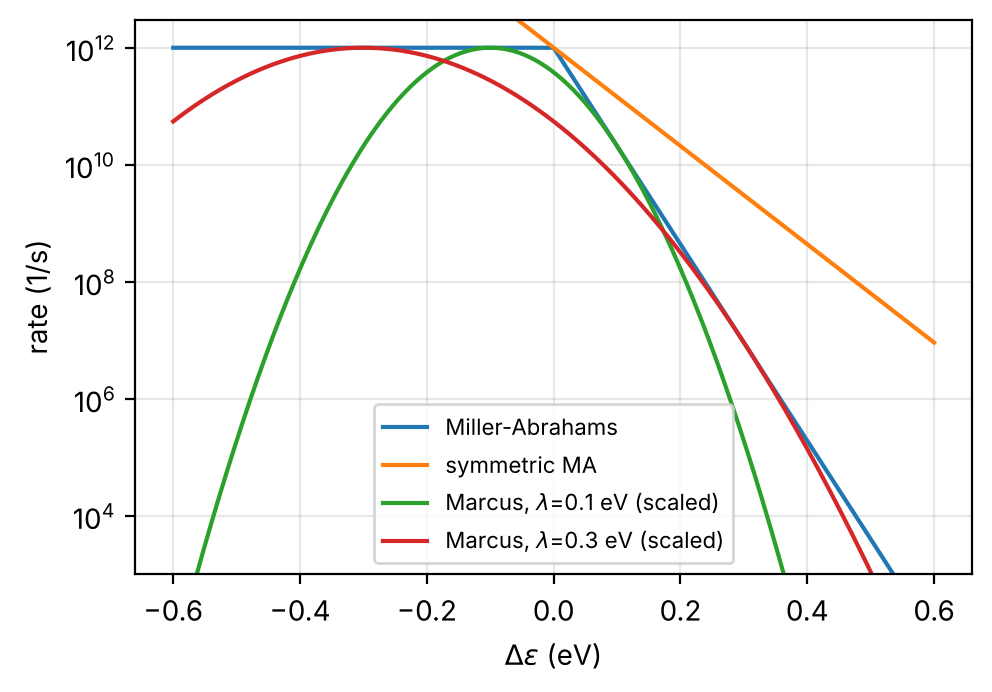

In [2]:
from orchid.rates import miller_abrahams, marcus, symmetric_ma
from orchid.constants import kB_eV
T = 300.0
dE = np.linspace(-0.6, 0.6, 400)
fig, ax = plt.subplots()
ax.semilogy(dE, miller_abrahams(dE, 1.0, T, alpha=0.0), label="Miller-Abrahams")
ax.semilogy(dE, symmetric_ma(dE, 1.0, T, alpha=0.0), label="symmetric MA")
for lam in (0.1, 0.3):
    k = marcus(dE, 0.01, T, lam)
    ax.semilogy(dE, k / k.max() * 1e12, label=f"Marcus, $\\lambda$={lam} eV (scaled)")
ax.set_xlabel(r"$\Delta\varepsilon$ (eV)"); ax.set_ylabel("rate (1/s)"); ax.legend(fontsize=8)
ax.set_ylim(1e3, 3e12);

Marcus rates peak at $-\Delta\varepsilon=\lambda$ and fall again further out (the *inverted region*).
MA rates stay flat for every downhill hop. Now check detailed balance numerically:

In [3]:
for name, f in [("MA", lambda d: miller_abrahams(d, 1.0, T, alpha=0.0)),
                ("Marcus", lambda d: marcus(d, 0.01, T, 0.2))]:
    d = np.linspace(-0.4, 0.4, 41)
    err = np.max(np.abs(np.log(f(d) / f(-d)) + d / (kB_eV * T)))
    print(f"{name:7s} max |ln(W_ij/W_ji) + dE/kT| = {err:.1e}")

MA      max |ln(W_ij/W_ji) + dE/kT| = 0.0e+00
Marcus  max |ln(W_ij/W_ji) + dE/kT| = 3.6e-15


### Disordered lattices
`Lattice(L, a, rc)` is a periodic cubic lattice with hops up to `rc` lattice constants.
`set_disorder(sigma, model)` draws the site energies: `"gaussian"` (uncorrelated), `"dipolar"`
(correlated, CDM-like) or `"exponential"`.

std: 0.1 0.1
nearest-neighbour correlation  gaussian -0.013   dipolar 0.646


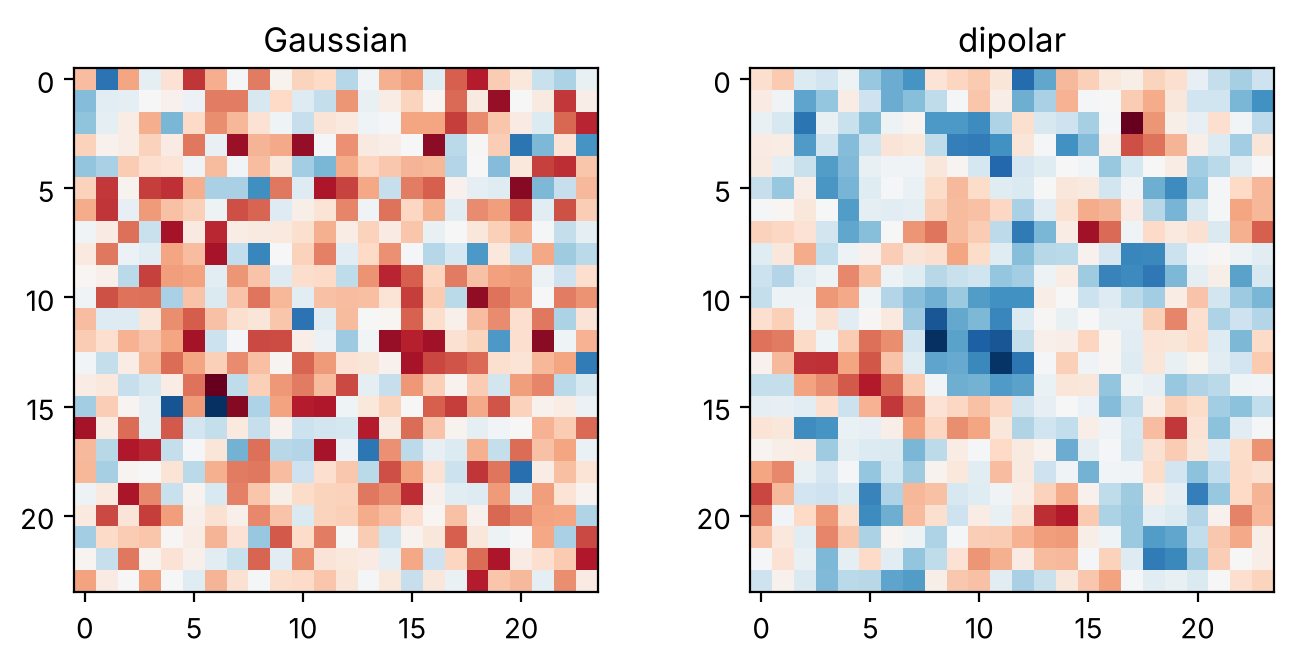

In [4]:
from orchid.lattice import Lattice
lat_g = Lattice(24, a=1.6e-9, seed=1).set_disorder(0.1)
lat_d = Lattice(24, a=1.6e-9, seed=1).set_disorder(0.1, "dipolar")
def corr(lat, shift):
    E = lat.energy.reshape(lat.shape)
    return np.mean(E * np.roll(E, shift, 0)) / np.var(E)
print("std:", lat_g.energy.std(), lat_d.energy.std())
print("nearest-neighbour correlation  gaussian %.3f   dipolar %.3f" % (corr(lat_g, 1), corr(lat_d, 1)))
fig, ax = plt.subplots(1, 2, figsize=(8, 3.4))
for a_, l, t in zip(ax, (lat_g, lat_d), ("Gaussian", "dipolar")):
    a_.imshow(l.energy.reshape(l.shape)[:, :, 0], cmap="RdBu_r"); a_.set_title(t); a_.grid(False)

The dipolar landscape is smooth, so neighbouring sites have similar energies. This correlation
produces the extended Poole–Frenkel $\ln\mu\propto\sqrt F$ regime of the correlated disorder model.

**Exercise.** Plot the Förster rate `orchid.rates.forster(0, r, T, tau, R0)` for $r=0.5\ldots5\,R_0$ and
confirm the $r^{-6}$ slope on a log–log plot.

<details><summary>Solution</summary>

```python
from orchid.rates import forster
r = np.logspace(np.log10(0.5), np.log10(5), 30)
k = forster(0.0, r, 300.0, 1e-9, 1.0)
print(np.polyfit(np.log(r), np.log(k), 1)[0])   # -> -6
```
</details>

**Exercise.** At what $\hat\sigma$ is a 0.1 eV Gaussian DOS at 300 K? At 200 K?

<details><summary>Solution</summary>

$\hat\sigma = 0.1/(8.617\times10^{-5}\cdot300) = 3.87$; at 200 K, 5.80.
</details>

## Quiz

Five questions on this section. Run the cell to see them, then grade yourself with
`quiz("01", answers="abcda")` (one letter per question). The same quiz runs in a terminal
with `orchid quiz 01`.

In [5]:
from orchid.tutorials import quiz
quiz("01")

Quiz 01: Hopping rates and energetic disorder

Q1. A Miller-Abrahams hop goes uphill by dE > 0 over distance r. Its rate is
    (a) nu0 exp(-2 alpha r) exp(-dE/2kT)
    (b) nu0 exp(-(dE + lambda)^2 / 4 lambda kT)
    (c) nu0 exp(-2 alpha r) exp(-dE/kT)
    (d) nu0 exp(-2 alpha r)

Q2. Which relation must every rate model in orchid.rates satisfy so that equilibrium is the Fermi-Dirac/Boltzmann state?
    (a) W_ij = W_ji
    (b) W_ij proportional to r^-6
    (c) sum_j W_ij = nu0
    (d) W_ij / W_ji = exp(-(E_j - E_i)/kT)

Q3. In Marcus theory, what happens to the rate as the driving force -dE grows beyond the reorganisation energy lambda?
    (a) It keeps increasing
    (b) It saturates at 2 pi J^2 / hbar
    (c) It decreases (inverted region)
    (d) It becomes temperature independent

Q4. The dimensionless disorder sigma-hat used throughout ORCHID is defined as
    (a) sigma^2 / kT
    (b) kT / sigma
    (c) sigma / kT
    (d) sigma / eFa

Q5. How do the Förster and Dexter exciton tran

In [6]:
# replace with your answers, e.g. "abcda"
# quiz("01", answers=".....")

<details><summary>Answer key</summary>

`cdcca`. Run `quiz("01", answers="cdcca")` to see the explanation for every question.
</details>

---
[Tutorial index](README.md) · ORCHID documentation · `orchid tutorials`